# AB Dor with amigo 0.1 and the 0.0.10 calibration
AB Dor and its calibrator HD 37093 (JWST program 1093, 2022-06-05), from calslopes to a companion fit, with
`amigo-pipeline` and `virgil`. The instrument is the paper's `calibration.npy` (amigo 0.0.10). AB Dor A has one
companion here, the low-mass star AB Dor C (~330 mas).

Both stars were observed in three visits. AB Dor: observations 12 and 13 in F380M, F430M and F480M (with two F480M
exposures each, of 5 and 13 groups), and observation 14 in F480M only, as five dithers. HD 37093: observations 15 and
16 in all three filters, and observation 17 as five F480M dithers. That makes 13 AB Dor and 11 HD 37093 exposures.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as np
import numpy as onp

import amigo_pipeline

from pathlib import Path
from IPython.display import Image, display
import matplotlib.pyplot as plt

load_dict = lambda x: np.load(x, allow_pickle=True).item()

# amigo-pipeline

The first stage of this notebook is to put the calslope data through the amigo-pipeline.

## Loading Data

In [2]:
import os
from amigo.files import get_files

home_path = "/media/morgana1/snert/max/data/"
data_dir = os.path.join(home_path, "JWST/AB-DOR/calslope_amigo-0.1/")
output_path = os.path.join(home_path, "pipeline_outputs/ab-dor_tauron")

# loading in the calslope files
files = get_files(
    data_dir,
    "calslope",
    EXP_TYPE="NIS_AMI",
    TARGPROP=["AB-DOR", "HD-37093"],
)
files = sorted(files, key=lambda f: f.filename())

## Instrument calibration
The paper's `calibration.npy`, converted by `convert_calibration_v2.py` with per-visit piston/tip/tilt shared across
filters (`ptt` sharing `program`, which amigo `be7cee0` and later require).

In [3]:
from amigo_pipeline.calibration import load_calibration

# path to saved instrumental state from base model calibration
calibration_path = os.path.join(
    home_path, "amigo_files/v_0.0.11/v2_from_calibration_npy_ptt_program"
)

# dict of model-construction inputs: detector, ramp_model, read, vis_model
# (AmigoModel), opd_calibration (AMIOptics) and defocus (per-filter values)
state = load_calibration(Path(calibration_path))

## Exposures
Exposures of one star, filter and roll share their visibilities, so the F480M exposures of each observation (two in
observations 12 and 13, five dithers in 14 and 17) are fitted with one set. The observations' rolls differ by
0.02-0.08°, more than `roll_tolerance`, so each observation keeps its own.

In [4]:
from amigo.model_fits import SplineVisFit
from amigo_pipeline.dataset import visibility_key

roll_tolerance = 1e-3  # degrees; recorded in model_recipe below
groups = {}
exposures = []

for f in files:
    role = "calibrator" if f[0].header["IS_PSF"] else "science"
    vis_key = visibility_key(f[0].header, role, groups, roll_tolerance)
    exposures.append(SplineVisFit(f, vis_key=vis_key))

## Building the model

In [5]:
from amigo_pipeline.dataset import DEFAULT_OPTICS
from amigo.core_models import AmigoModel
from amigo.optical_models import AMIOptics

filters = sorted({exp.filter for exp in exposures})

model = AmigoModel(
    exposures,
    optics=AMIOptics(
        opd_calibration=state["opd_calibration"],
        filters=filters,
        **DEFAULT_OPTICS,
    ),
    detector=state["detector"],
    ramp_model=state["ramp_model"],
    read=state["read"],
    vis_model=state["vis_model"],
)

# setting model defocus
for f in filters:
    model = model.set(f"params.defocus.{f}", np.asarray(state["defocus"][f]))

## Pairs
Each AB Dor observation is calibrated by every HD 37093 exposure in its filter, which gives seven products: F380M and
F430M from observations 12 and 13, and F480M from 12, 13 and 14. The first HD 37093 exposure in each filter
(observation 15) is the reference the basis and the null are built at.

In [6]:
pairs = []
for f in filters:
    calibrators = sorted(
        exp.key for exp in exposures if exp.filter == f and exp.calibrator
    )
    visits = {}
    for exp in exposures:
        if exp.filter == f and not exp.calibrator:
            visits.setdefault(exp.vis_key, []).append(exp)
    for visit in visits.values():
        pairs.append(
            {
                "name": f"{visit[0].star}_{f}_obs{visit[0].observation}",
                "science": [exp.key for exp in visit],
                "calibrator": calibrators,
                "reference": calibrators[0],
            }
        )

## Cache provenance
The files the model is built from, and how it is built from them.

In [7]:
from amigo_pipeline.storage import file_hash

# The pipeline keys its cached initial state on these file hashes and this recipe instead
# of the model's raw arrays, so GPU roundoff when rebuilding the model can't invalidate the
# cache: on resume it restores the saved arrays. The recipe must describe everything above
# that decides how the model is built, so update it (or bump "builder") when that changes.
source_files = {
    str(path): file_hash(path)
    for path in [
        *Path(calibration_path).iterdir(),
        *(Path(f.filename()) for f in files),
    ]
    if path.is_file()
}
model_recipe = {
    "builder": "ab-dor_pipeline_v0.1",
    "exposures": {"roll_tolerance": roll_tolerance},
    "optics": {**DEFAULT_OPTICS, "filters": filters},
    "vis_model": "PlaceholderVisModel",
}

## Run the pipeline
`run()` resumes: stages already completed in `output` with the same inputs are loaded, not refitted. With
`strict=False`, a completed stage whose inputs differ is reused with a warning instead of raising. A new folder runs
everything, which took about 5½ hours on tauron's RTX 3090 (2026-11-20).

In [8]:
pipeline = amigo_pipeline.Pipeline(
    exposures,
    model,
    pairs,
    output=output_path,
    roll_tolerance=roll_tolerance,
    source_files=source_files,
    model_recipe=model_recipe,
)
discos, cross = pipeline.run(
    strict=False,
)

products: cached inputs differ; reusing the cached stage (strict=False)


The pipeline draws its own figures: the instrument fit to HD 37093's first exposure (F480M, observation 15), AB Dor's
first exposure fitted as a point source (C shows in the residuals), and the DISCOs.

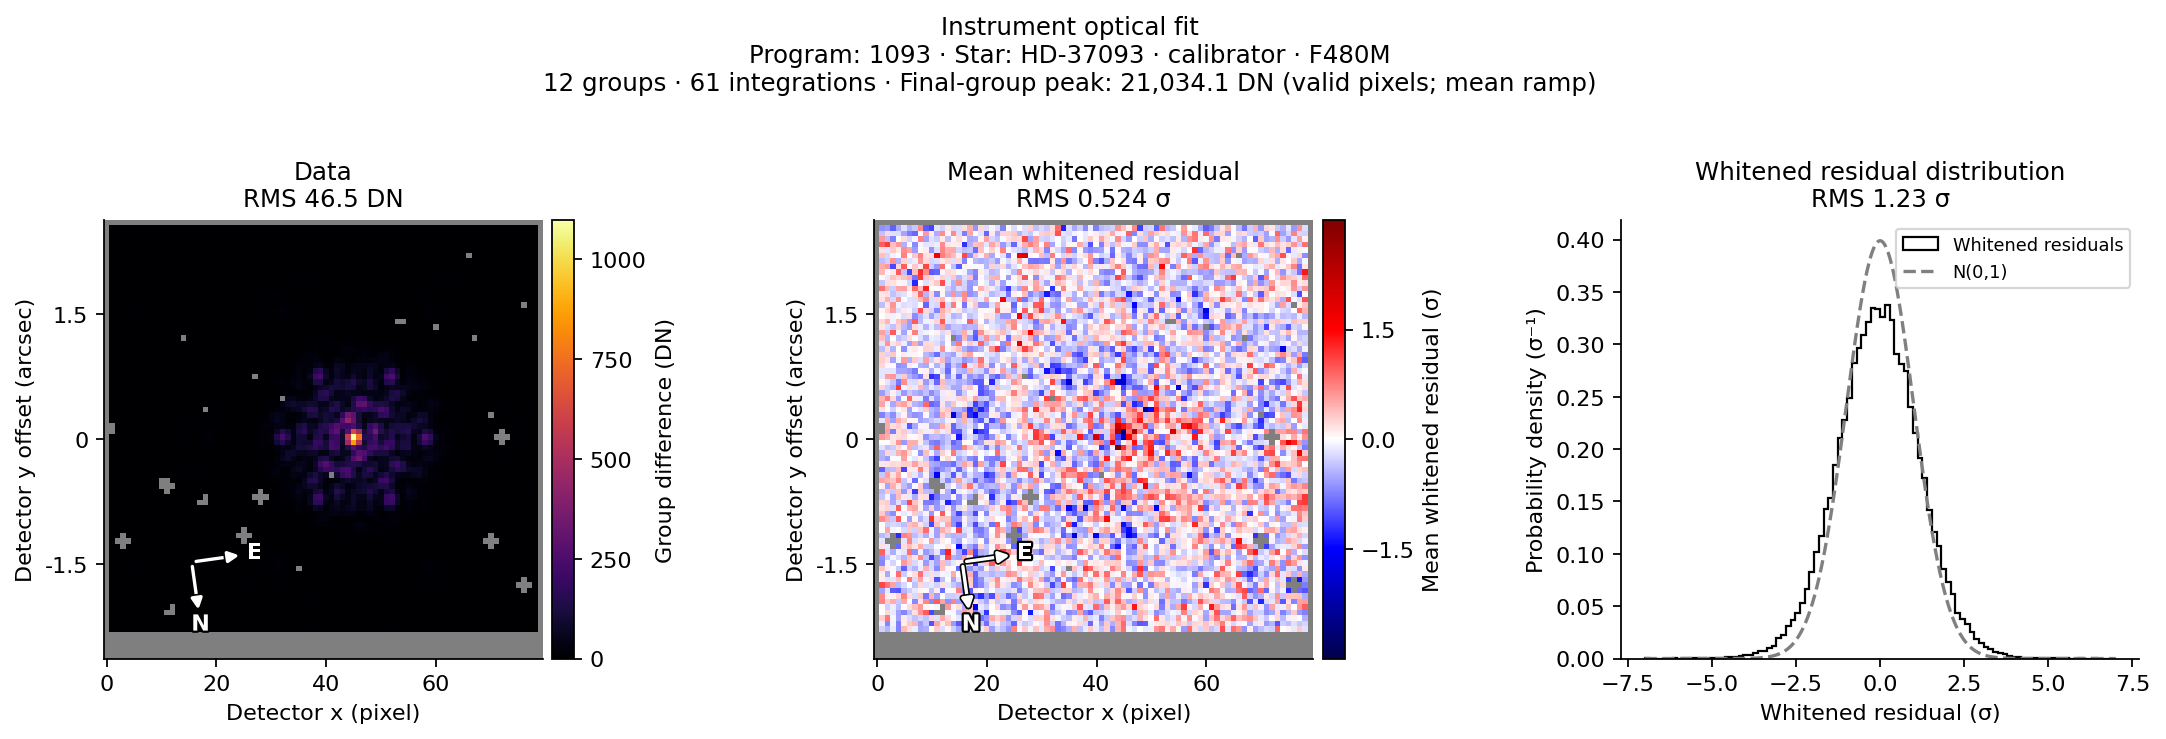

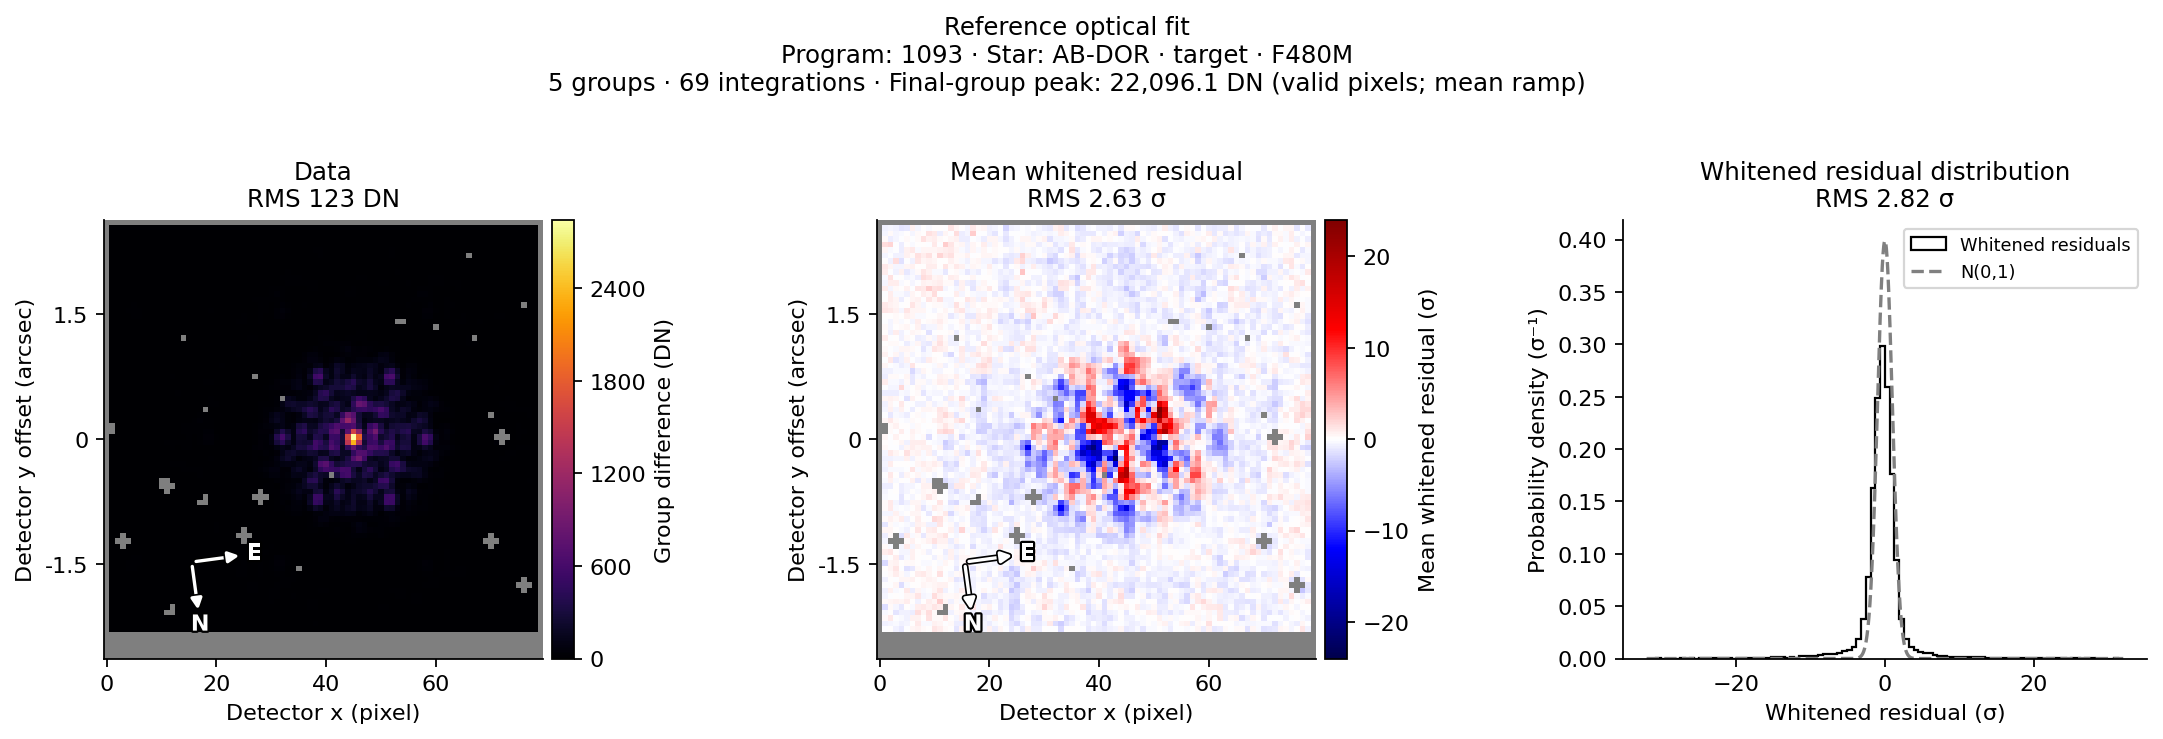

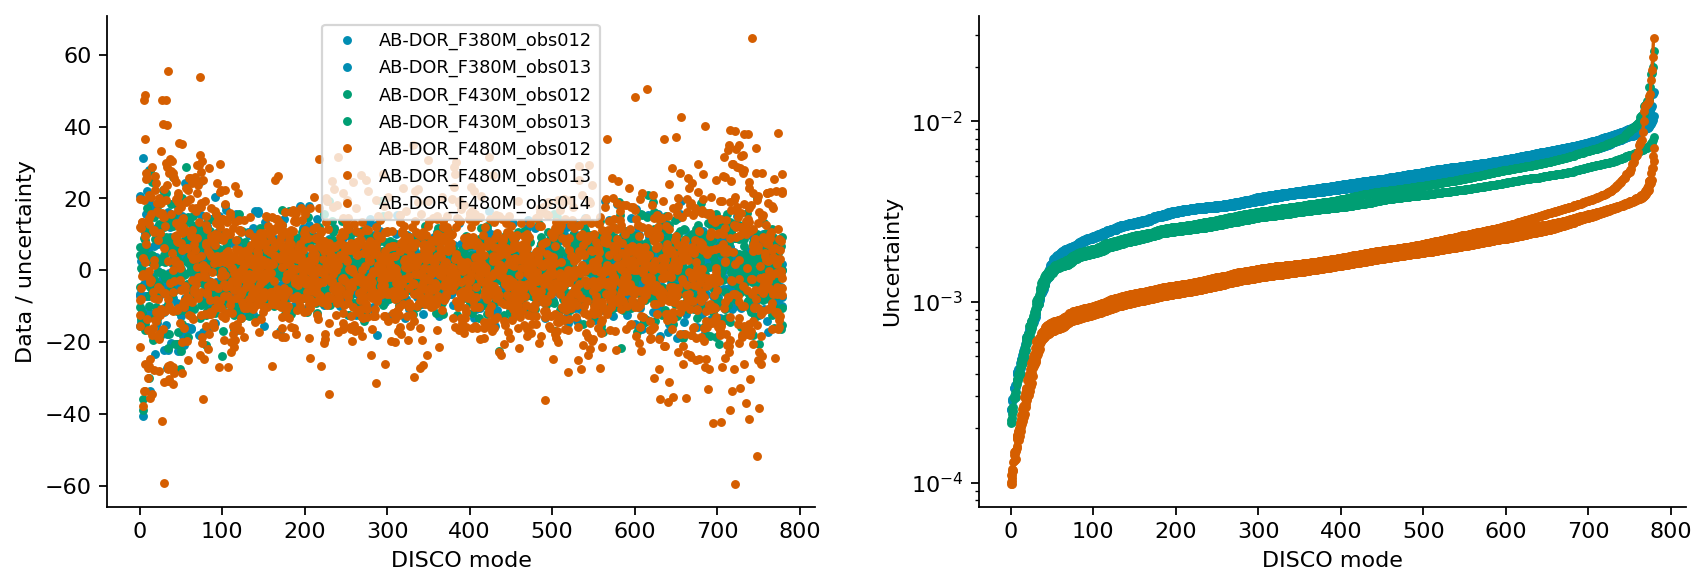

In [9]:
for figure in [
    "instrument/pixels_0.png",
    "reference/pixels_0.png",
    "products/discos.png",
]:
    display(Image(filename=str(Path(output_path) / figure)))

## How the fits went
Every pipeline fit, one row per exposure. `residual_rms_sigma` is the RMS of the whitened detector residuals, so 1
means the fit reaches the noise and larger values are model error (or underestimated noise). `gradient` is the largest
normalised gradient at the end of the fit (the acceptance threshold is 1e-6).

In [10]:
import sys

sys.path.insert(0, "..")  # pipeline_plots.py, shared with the 0.2 notebooks
import pipeline_plots

pipeline_plots.fit_summary(output_path).round({"residual_rms_sigma": 2, "minutes": 1})

filter        role  residual_rms_sigma  \
stage      exposure                                                   
instrument 01093_015_02_03_1  F480M  calibrator                1.23   
           01093_015_03_03_1  F430M  calibrator                1.27   
           01093_015_04_03_1  F380M  calibrator                1.31   
           01093_016_02_03_1  F480M  calibrator                1.28   
           01093_016_03_03_1  F430M  calibrator                1.37   
           01093_016_04_03_1  F380M  calibrator                1.66   
           01093_017_02_03_1  F480M  calibrator                1.25   
           01093_017_02_03_2  F480M  calibrator                1.25   
           01093_017_02_03_3  F480M  calibrator                1.22   
           01093_017_02_03_4  F480M  calibrator                1.31   
           01093_017_02_03_5  F480M  calibrator                1.26   
reference  01093_012_02_03_1  F480M      target                2.82   
           01093_012_03_03_1  F430M      target                3.54   
           01093_012_04_03_1  F380M      target                6.36   
           01093_012_05_03_1  F480M      target                2.73   
           01093_013_02_03_1  F480M      target                2.64   
           01093_013_03_03_1  F430M      target                3.38   
           01093_013_04_03_1  F380M      target                5.83   
           01093_013_05_03_1  F480M      target                2.62   
           01093_014_02_03_1  F480M      target                2.79   
           01093_014_02_03_2  F480M      target                2.73   
           01093_014_02_03_3  F480M      target                2.82   
           01093_014_02_03_4  F480M      target                2.79   
           01093_014_02_03_5  F480M      target                2.75   
visibility 01093_012_02_03_1  F480M      target                1.44   
           01093_012_05_03_1  F480M      target                1.73   
           01093_012_03_03_1  F430M      target                1.84   
           01093_012_04_03_1  F380M      target                2.88   
           01093_013_02_03_1  F480M      target                1.42   
           01093_013_05_03_1  F480M      target                1.73   
           01093_013_03_03_1  F430M      target                1.75   
           01093_013_04_03_1  F380M      target                2.58   
           01093_014_02_03_1  F480M      target                1.46   
           01093_014_02_03_2  F480M      target                1.41   
           01093_014_02_03_3  F480M      target                1.44   
           01093_014_02_03_4  F480M      target                1.48   
           01093_014_02_03_5  F480M      target                1.40   
           01093_015_02_03_1  F480M  calibrator                1.18   
           01093_015_03_03_1  F430M  calibrator                1.15   
           01093_015_04_03_1  F380M  calibrator                1.17   
           01093_016_02_03_1  F480M  calibrator                1.19   
           01093_016_03_03_1  F430M  calibrator                1.24   
           01093_016_04_03_1  F380M  calibrator                1.31   
           01093_017_02_03_1  F480M  calibrator                1.22   
           01093_017_02_03_2  F480M  calibrator                1.21   
           01093_017_02_03_3  F480M  calibrator                1.20   
           01093_017_02_03_4  F480M  calibrator                1.27   
           01093_017_02_03_5  F480M  calibrator                1.23   

                                       status      gradient  minutes  
stage      exposure                                                   
instrument 01093_015_02_03_1  gradient_target  1.175593e-07     20.3  
           01093_015_03_03_1  gradient_target  1.175593e-07     20.3  
           01093_015_04_03_1  gradient_target  1.175593e-07     20.3  
           01093_016_02_03_1  gradient_target  1.175593e-07     20.3  
           01093_016_03_03_1  gradient_target  1.175

Whitened detector residuals for every exposure, from the point-source fit (calibrators: instrument stage; AB Dor:
reference stage) and from the visibility fit, one figure per filter and star. Structure that survives the visibility
fit is not explained by the visibility basis.

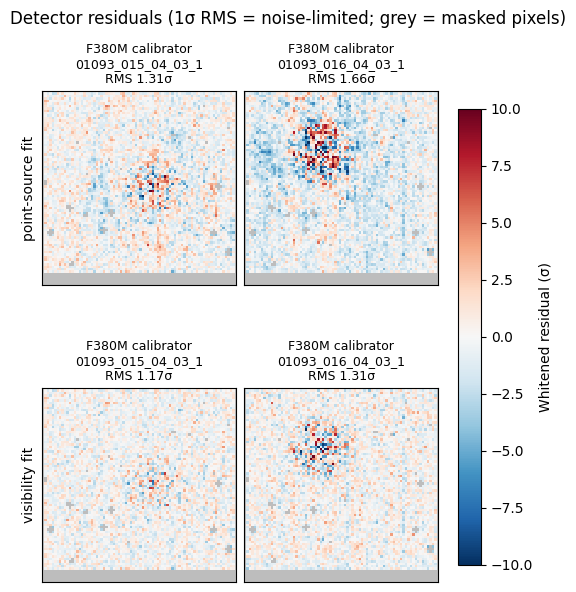

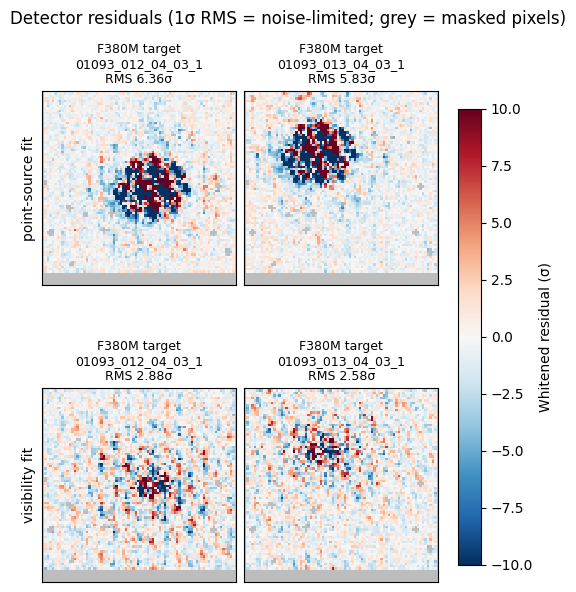

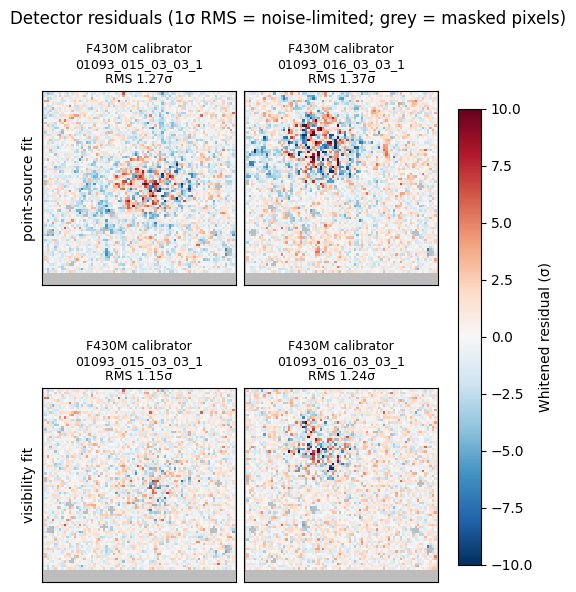

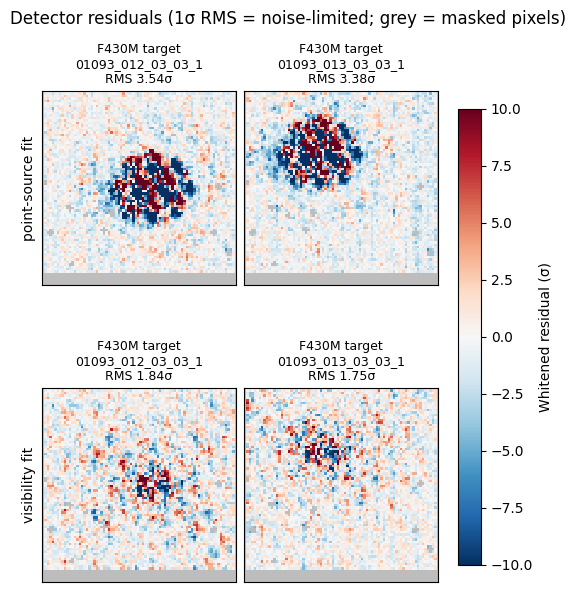

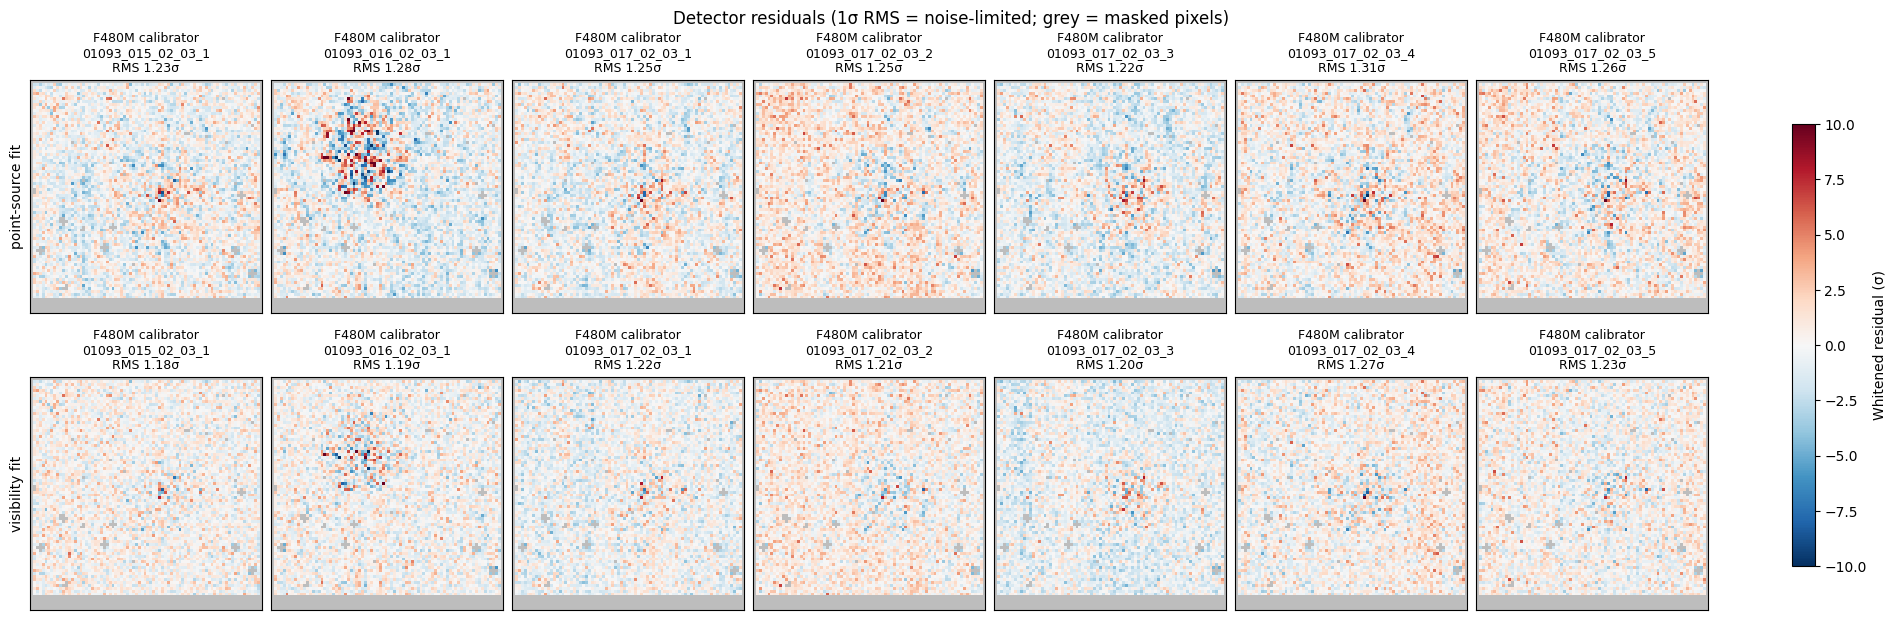

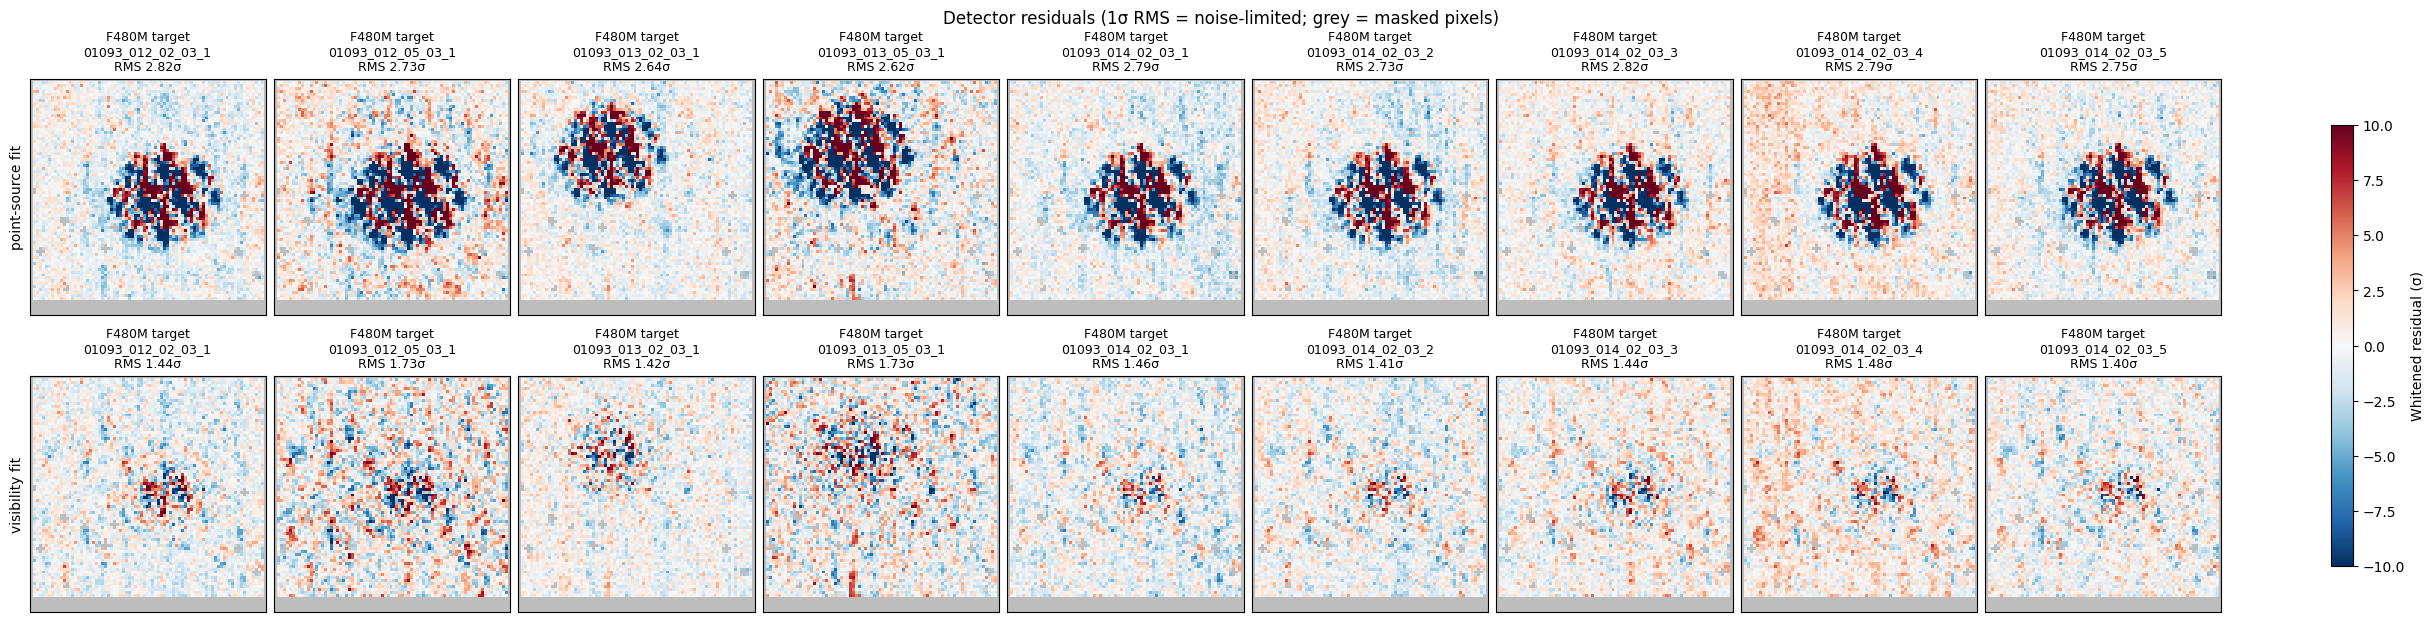

In [11]:
for f in filters:
    for calibrator in (True, False):
        keys = [
            exp.key
            for exp in exposures
            if exp.filter == f and exp.calibrator == calibrator
        ]
        pipeline_plots.residual_grid(output_path, keys=keys)
        plt.show()

## Visibilities in the uv plane
Each fit's visibility coefficients times the basis modes give the log-visibility it fitted on the uv grid, relative to
the optical model. Science and calibrator share a colour scale, so the instrument signature they have in common is
visible; the calibrated column (science minus calibrator) is what goes into the DISCOs. Axes are in the instrument
frame, not on the sky.

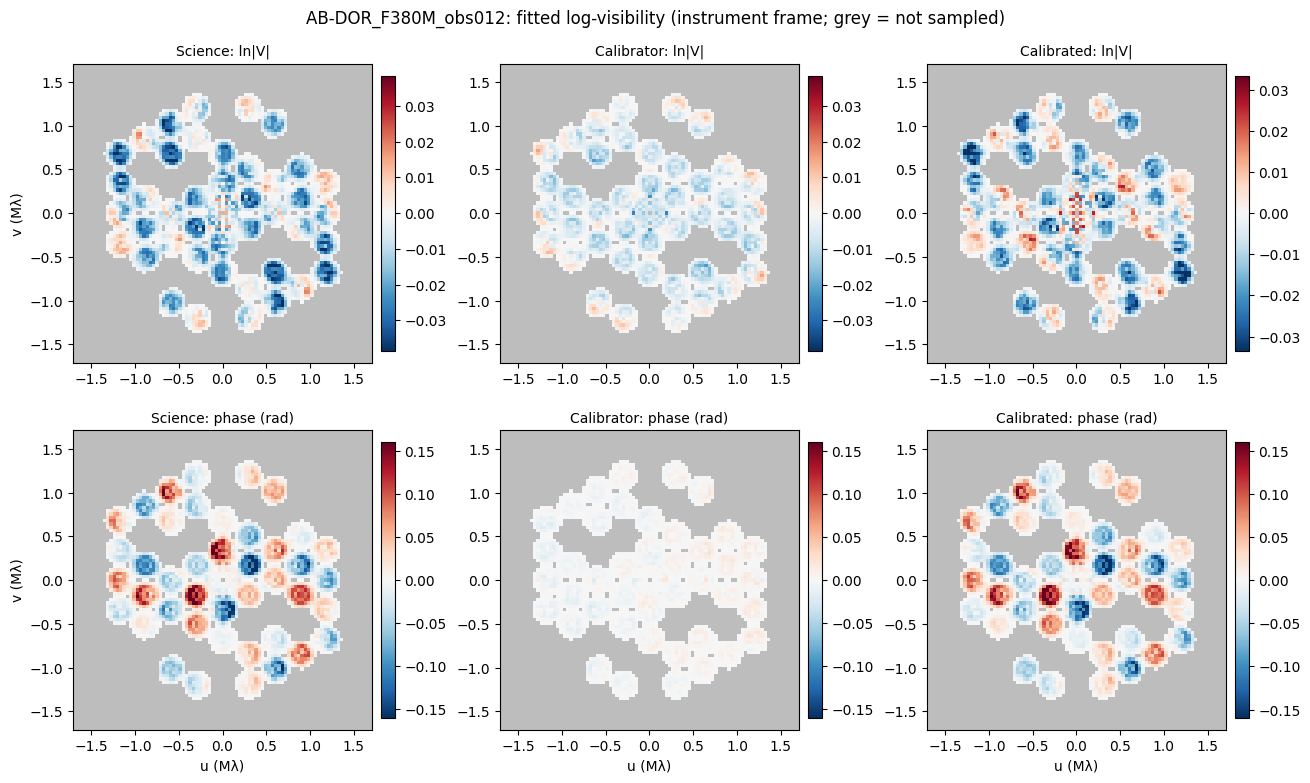

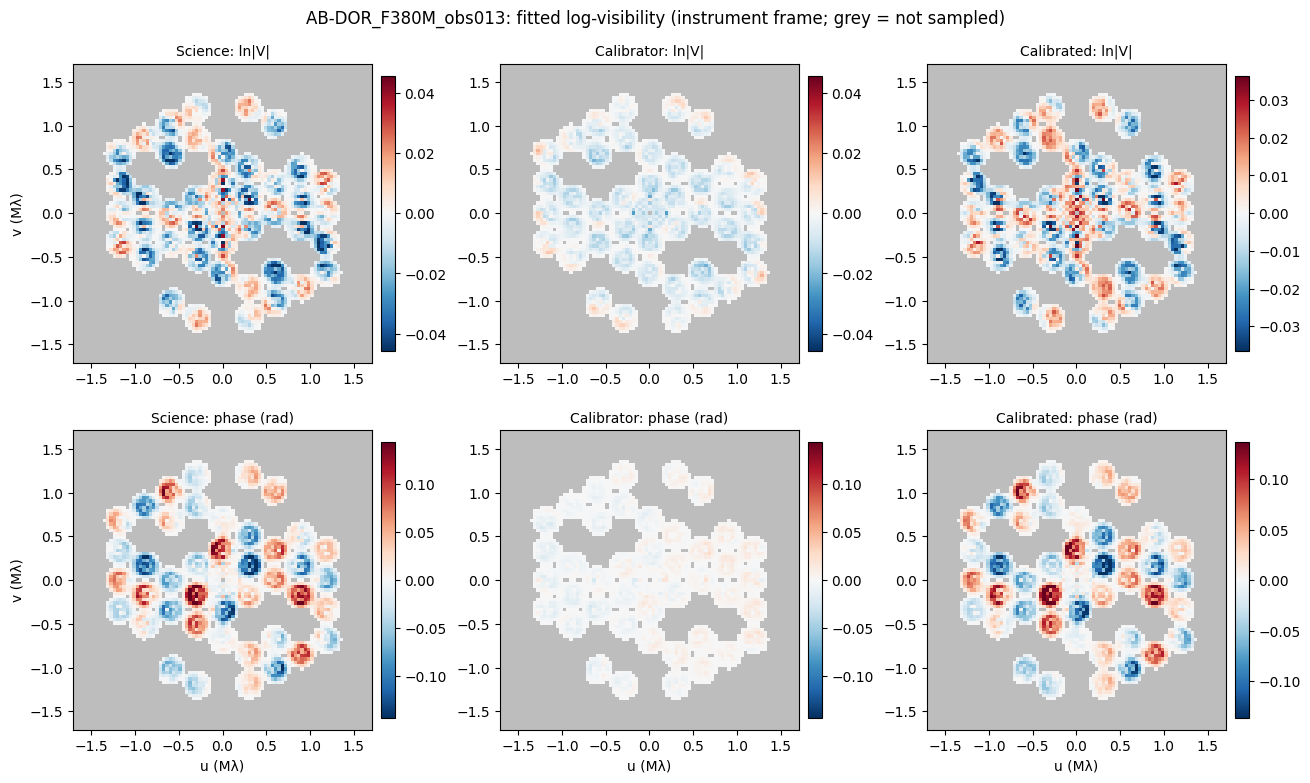

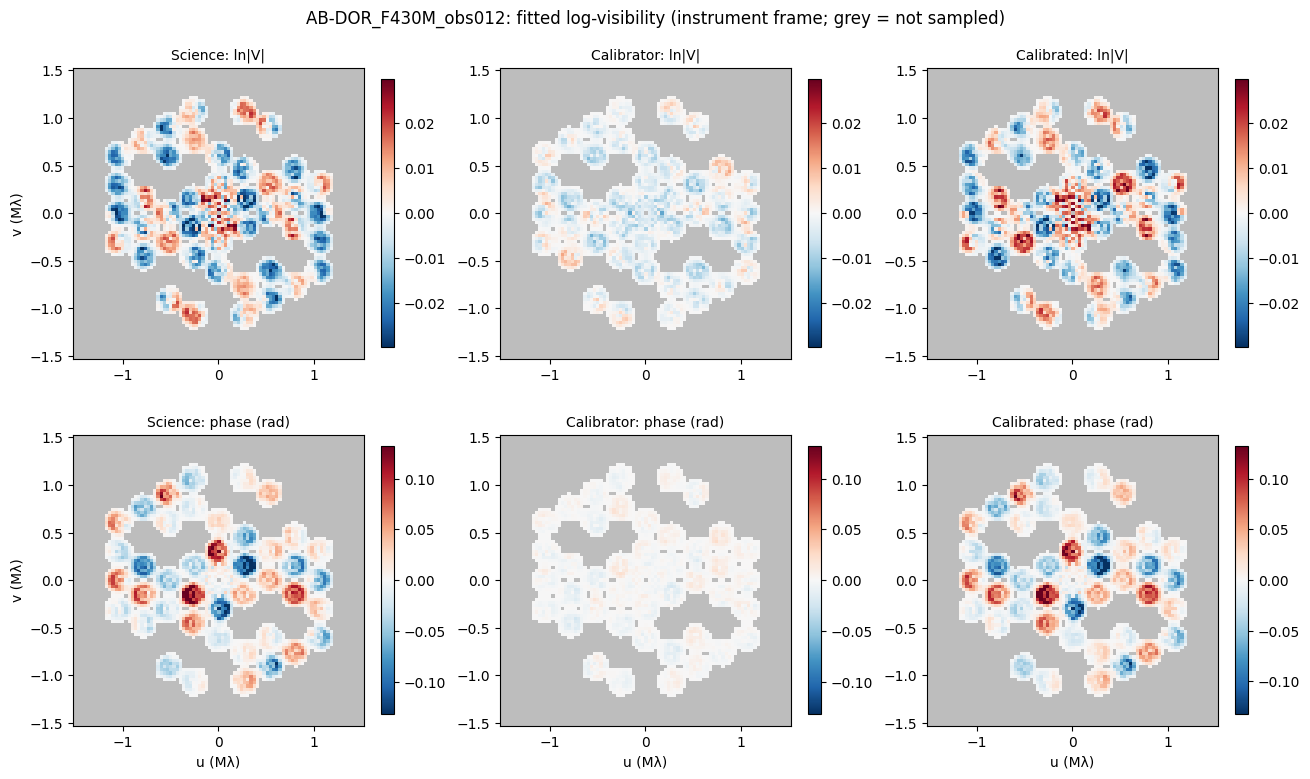

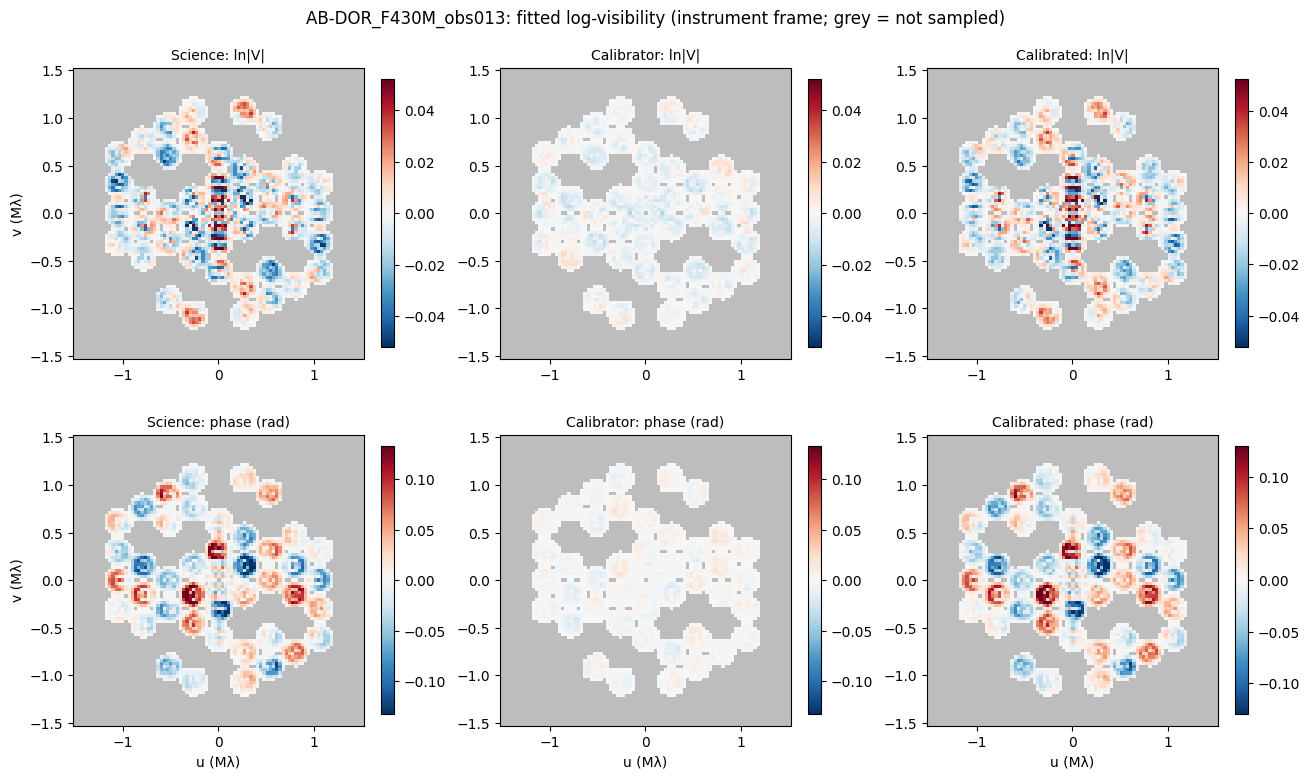

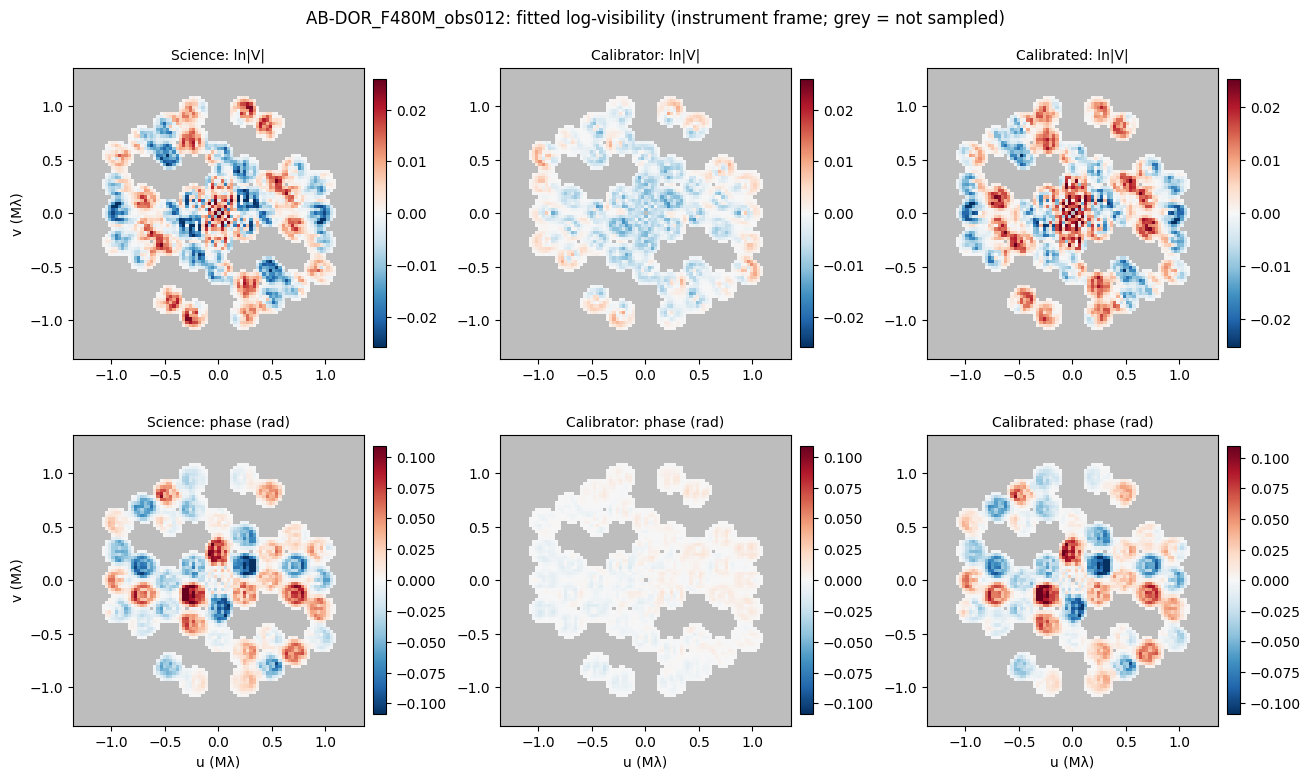

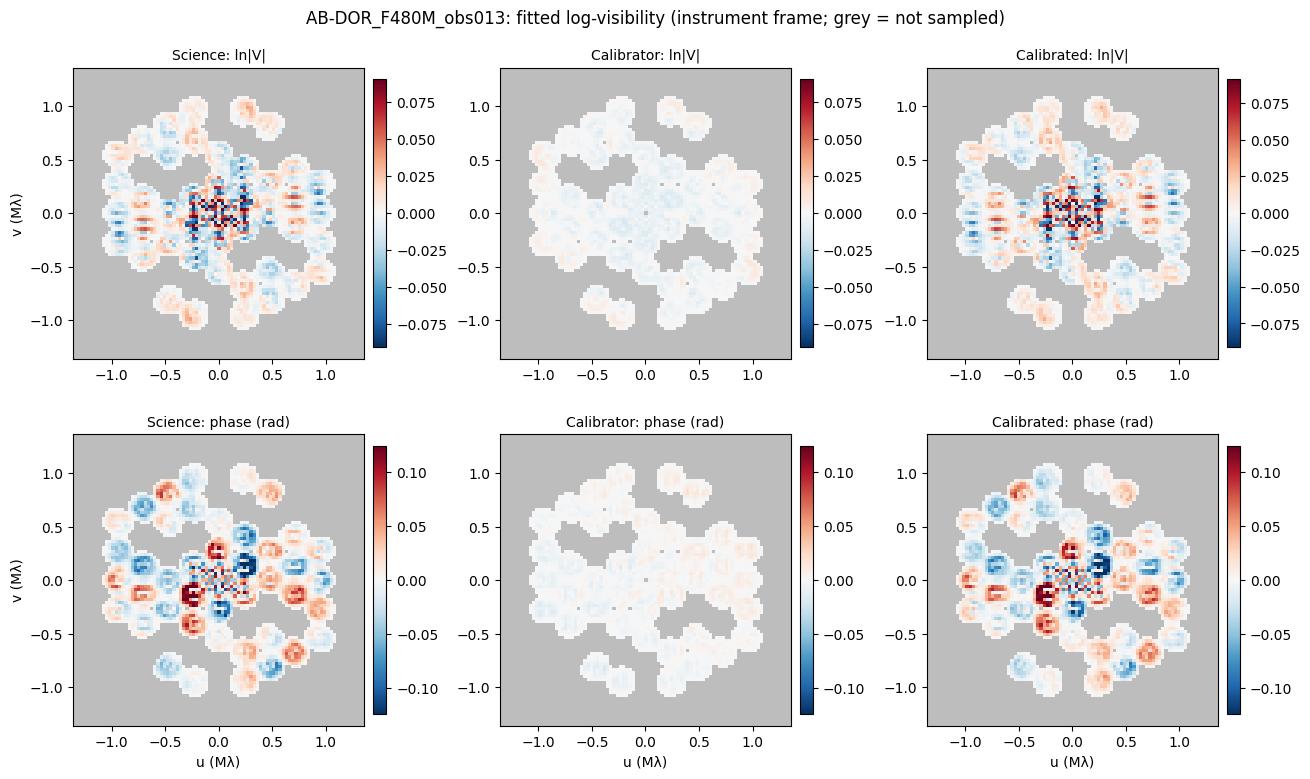

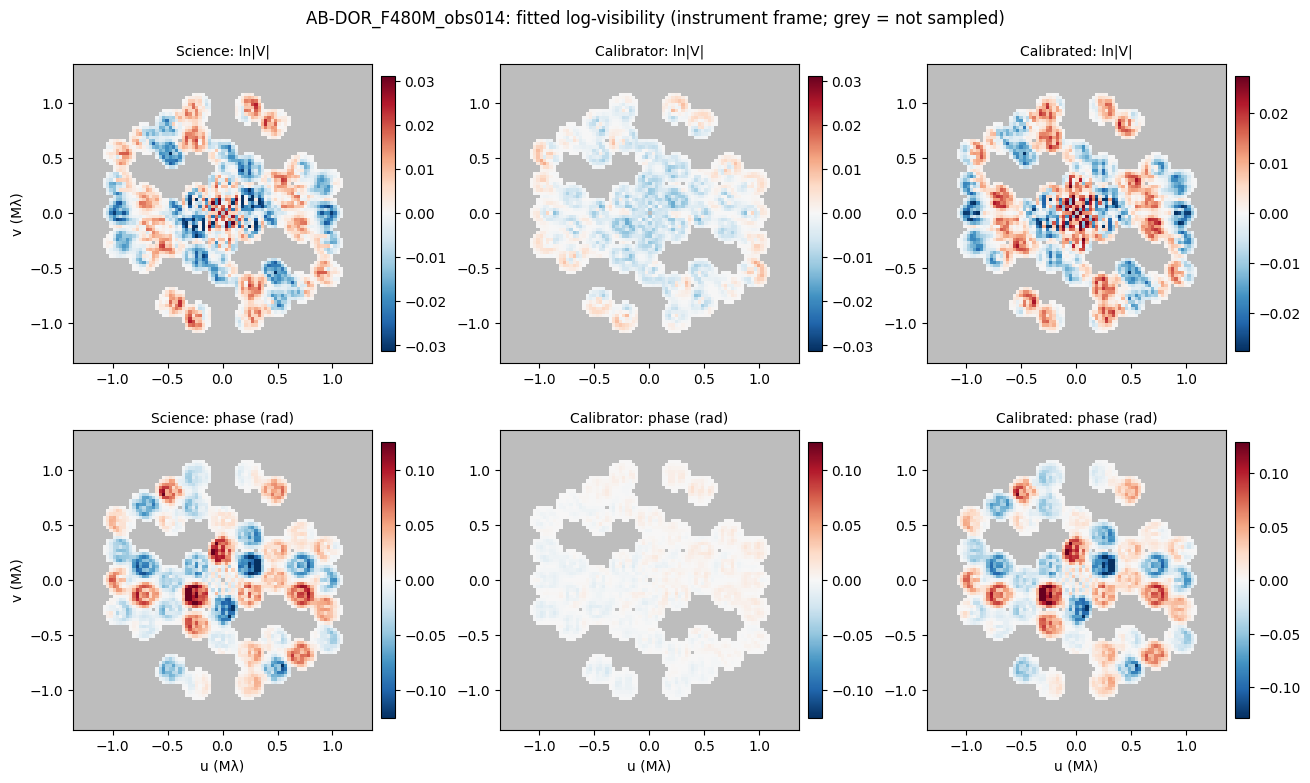

In [12]:
for name, disco in discos.items():
    pipeline_plots.uv_visibilities(output_path, name, disco)
    plt.show()

# virgil

## AB Dor C
Virgil's binary pipeline on each product's DISCOs, fitting one companion.

If the fit's reduced χ² is above 1 with the errors as quoted, the quoted errors are too small; the `x √χ²` columns
scale them up to make χ²/dof = 1 (a rough correction: it assumes the excess scatter is white).

PA here is east of north (Virgil's convention). The AMIGO paper's tables give 90° − PA (the angle from east towards
north): its AB Dor C at 169.48° is 280.52° east of north.

`detection_sigma` is the local significance of the companion: √Δχ² for one more point source at a position fixed in
advance, with no look-elsewhere correction. `detection_sigma_scaled` divides Δχ² by the reduced χ² first, the same
rough correction as the `x √χ²` columns. Virgil's `local_nsigma` is the same number but stops at about 37.5σ, where
float64 runs out of tail probability, which every product here passes (2026-11-20: √Δχ² is 122–252, or 21–25 scaled).

In [13]:
from virgil.models import PointSource, System
from virgil.pipeline import BinaryPipeline

from amigo.discos import to_virgil

import pandas as pd

/home/max/conda/miniconda3/envs/0.1/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [14]:
results = {
    name: BinaryPipeline(
        to_virgil(disco),
        output=Path(output_path) / "binary" / name,
        max_sep_mas=600.0,
        n_flux=80,
    ).run()
    for name, disco in discos.items()
}

rows = {}
for name, res in results.items():
    c, s = res.summary["companion"], res.summary["chi2"]
    k = onp.sqrt(s["companion_reduced"])
    dchi2 = max(res.summary["search"]["delta_chi2"], 0.0)
    _, filt, obs = name.split("_")
    rows[(filt, obs)] = {
        "sep_mas": c["sep_mas"],
        "sep_err": c["sep_err_mas"],
        "sep_err_x_sqrt_chi2": k * c["sep_err_mas"],
        "pa_deg": c["pa_deg"],
        "pa_err": c["pa_err_deg"],
        "pa_err_x_sqrt_chi2": k * c["pa_err_deg"],
        "delta_mag": c["delta_mag"],
        "chi2_reduced": s["companion_reduced"],
        "detection_sigma": onp.sqrt(dchi2),
        "detection_sigma_scaled": onp.sqrt(dchi2 / s["companion_reduced"]),
    }
C_table = pd.DataFrame(rows).T
C_table.index.names = ["filter", "observation"]
C_table.round(2)

sep_mas  sep_err  sep_err_x_sqrt_chi2  pa_deg  pa_err  \
filter observation                                                          
F380M  obs012        330.02     0.57                 3.38  281.00    0.10   
       obs013        331.31     0.56                 2.92  280.67    0.10   
F430M  obs012        331.80     0.58                 3.40  280.45    0.09   
       obs013        330.29     0.62                 3.47  280.60    0.09   
F480M  obs012        332.65     0.39                 3.92  280.35    0.06   
       obs013        325.75     0.37                 3.69  280.47    0.05   
       obs014        329.91     0.34                 3.62  280.32    0.05   

                    pa_err_x_sqrt_chi2  delta_mag  chi2_reduced  \
filter observation                                                
F380M  obs012                     0.59       4.48         34.76   
       obs013                     0.50       4.40         27.24   
F430M  obs012                     0.55       4.50         33.77   
       obs013                     0.52       4.48         31.20   
F480M  obs012                     0.56       4.59        103.00   
       obs013                     0.55       4.54         99.38   
       obs014                     0.52       4.51        112.84   

                    detection_sigma  detection_sigma_scaled  
filter observation                                           
F380M  obs012                121.92                   20.68  
       obs013                129.42                   24.80  
F430M  obs012                136.97                   23.57  
       obs013                139.10                   24.90  
F480M  obs012                228.31                   22.50  
       obs013                228.15                   22.89  
       obs014                251.94                   23.72

The AMIGO paper's AB Dor C (Table 4, per-filter fits), with its PA converted to east of north, next to each product
here. The paper used one exposure of each star per filter, without dithers: AB Dor's observation 12 (the 5-group F480M
exposure) calibrated by HD 37093's observation 15. So `obs012` is the closest match, though here its F480M product
also has the 13-group exposure, and every product is calibrated by all of HD 37093's exposures in its filter. The
paper's joint fit to all three filters gives 328.85 +0.48/−0.85 mas and PA 169.482° (280.518° east of north).

(2026-11-20: every product's separation is within 5.2 mas of the paper's and its PA within 0.52°, within 1.3 times the
√χ²-scaled errors above. Δmag is 0.10–0.21 mag fainter than the paper's in every product. The reduced χ² is 27–35 in
F380M and F430M and 99–113 in F480M; in the figures below, the residuals are larger in phase than in log amplitude
(RMS 9.7σ against 3.2σ for F380M obs012, 16.3σ against 6.0σ for F480M obs012) and strongest at short baselines.)

In [15]:
paper_C = pd.DataFrame(
    {
        "F380M": (329.9, 169.521, 4.301),
        "F430M": (328.58, 169.468, 4.357),
        "F480M": (327.5, 169.447, 4.377),
    },
    index=["sep_mas", "paper_pa", "delta_mag"],
).T
paper_C["pa_deg"] = (90 - paper_C["paper_pa"]) % 360
C_table[["sep_mas", "pa_deg", "delta_mag"]].join(
    paper_C[["sep_mas", "pa_deg", "delta_mag"]], on="filter", rsuffix=" (paper)"
).round(2)

sep_mas  pa_deg  delta_mag  sep_mas (paper)  \
filter observation                                                
F380M  obs012        330.02  281.00       4.48           329.90   
       obs013        331.31  280.67       4.40           329.90   
F430M  obs012        331.80  280.45       4.50           328.58   
       obs013        330.29  280.60       4.48           328.58   
F480M  obs012        332.65  280.35       4.59           327.50   
       obs013        325.75  280.47       4.54           327.50   
       obs014        329.91  280.32       4.51           327.50   

                    pa_deg (paper)  delta_mag (paper)  
filter observation                                     
F380M  obs012               280.48               4.30  
       obs013               280.48               4.30  
F430M  obs012               280.53               4.36  
       obs013               280.53               4.36  
F480M  obs012               280.55               4.38  
       obs013               280.55               4.38  
       obs014               280.55               4.38

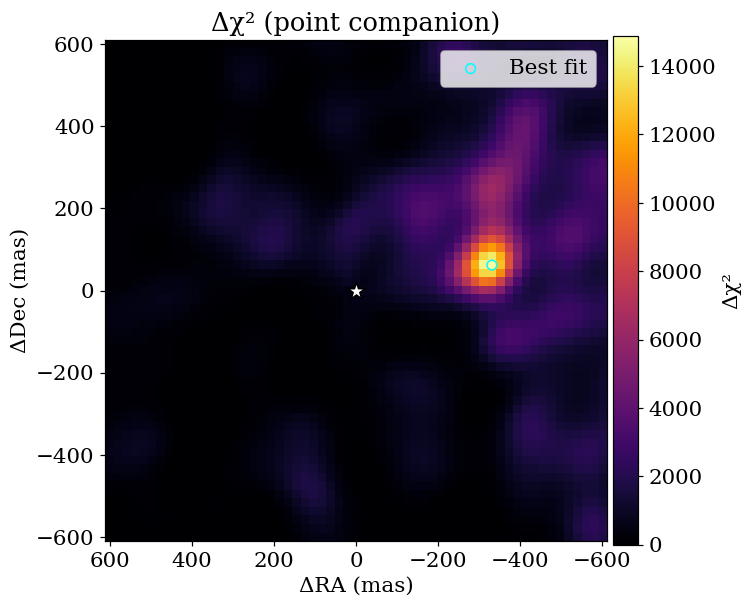

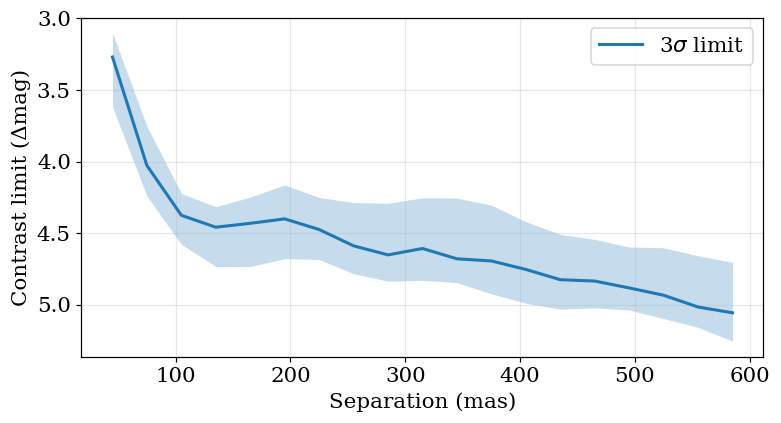

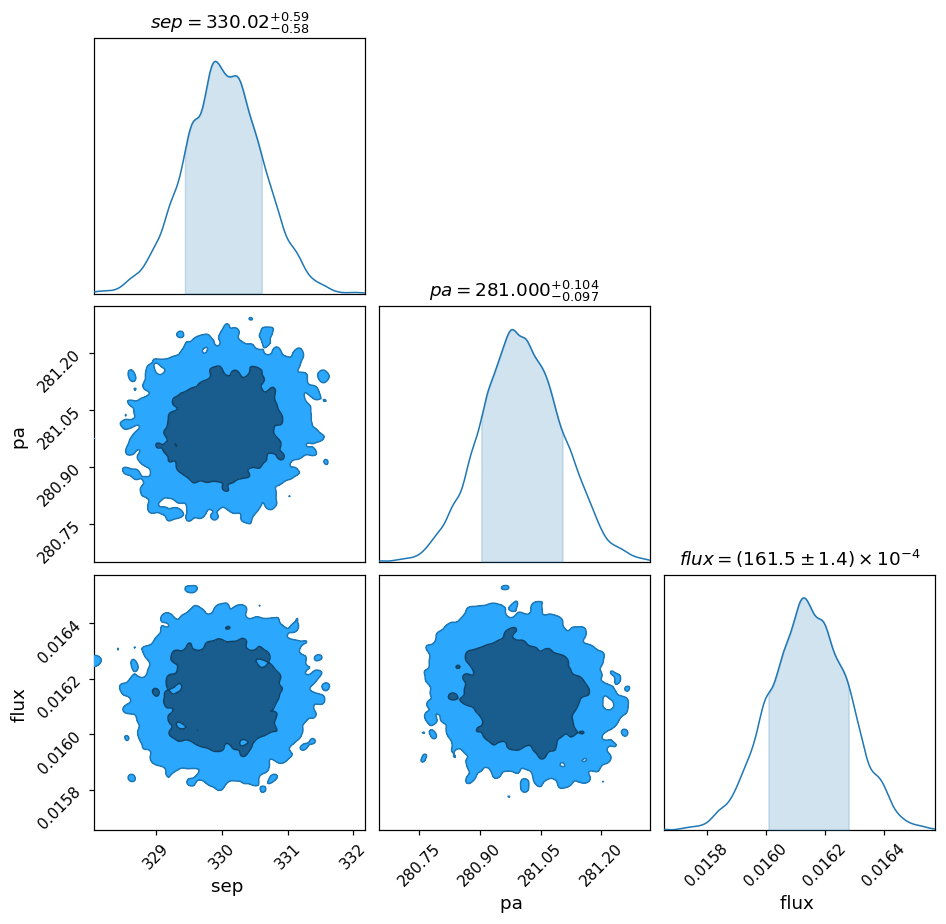

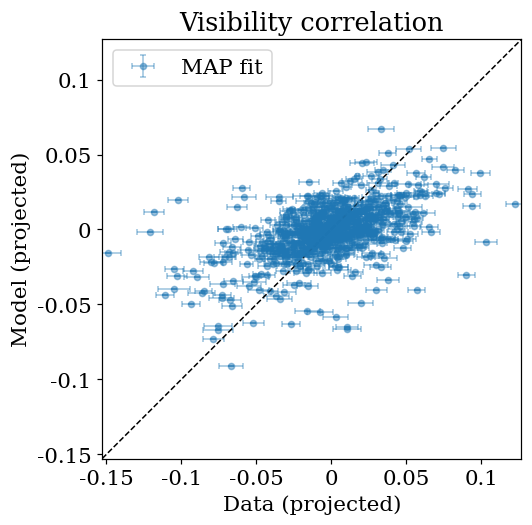

In [16]:
plots = Path(output_path) / "binary" / next(iter(results)) / "plots"
for plot in [
    "search_delta_chi2",
    "limits_contrast_curve",
    "posterior_corner",
    "fit_correlation",
]:
    display(Image(filename=str(plots / f"{plot}.png")))

Calibrated visibilities against the best-fit binary, drawn in the uv plane in units of σ. Both are projected the same
way as the DISCOs, so this is the comparison Virgil fits, laid out in uv. Neighbouring uv points are correlated, so
the residual RMS is a guide rather than a χ²; the reduced χ² is in the table above.

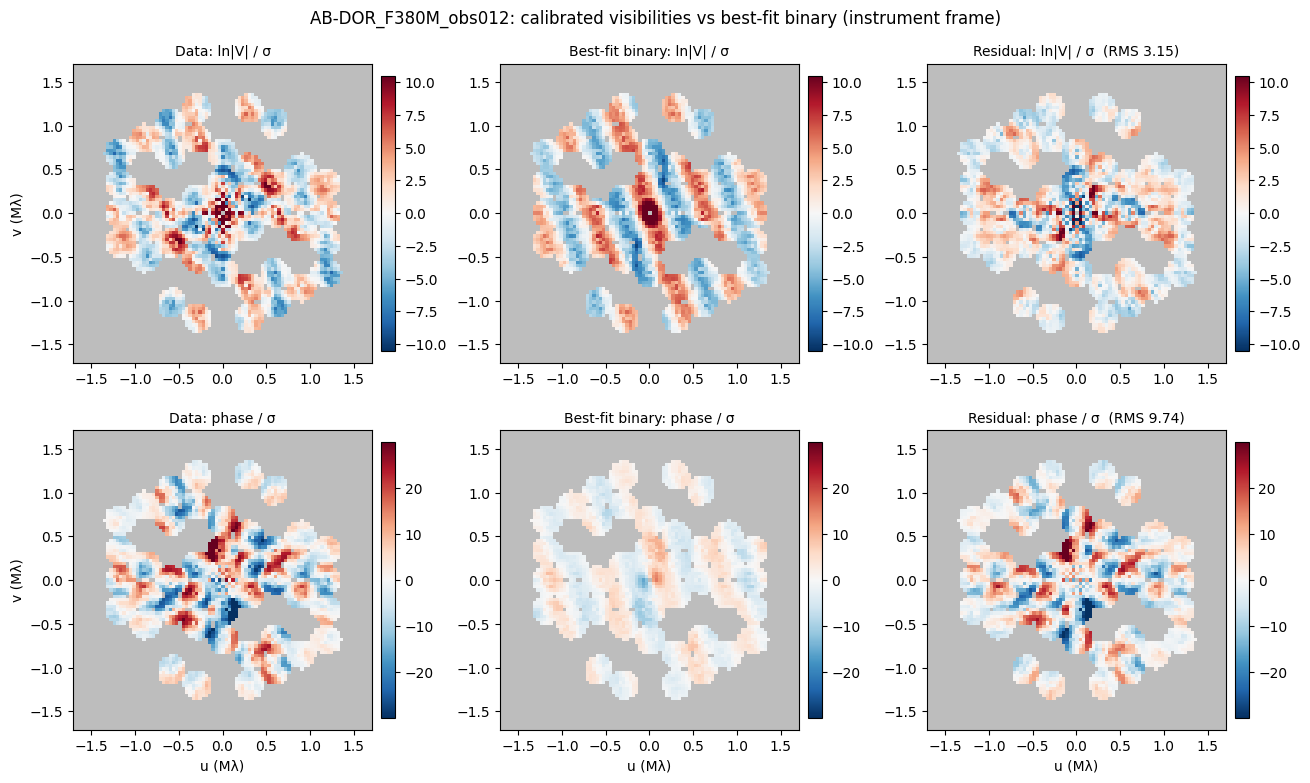

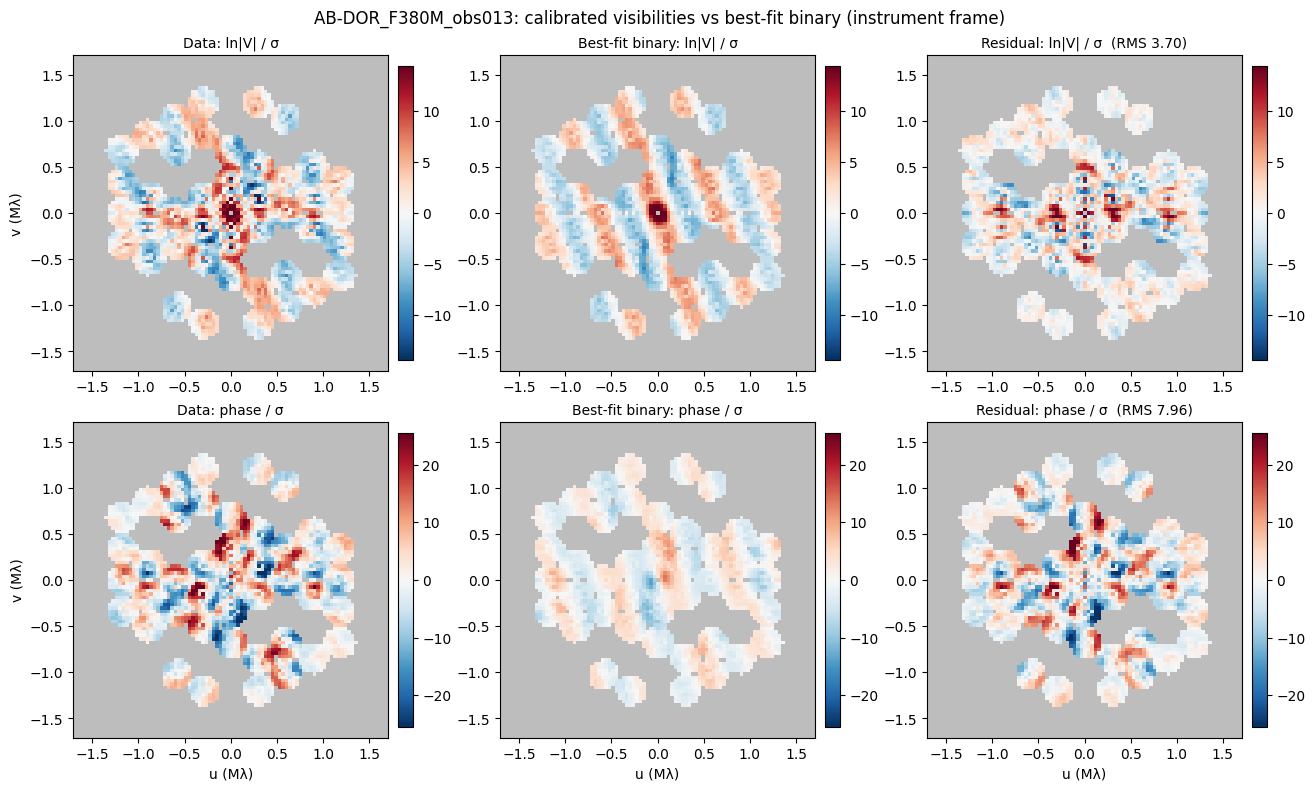

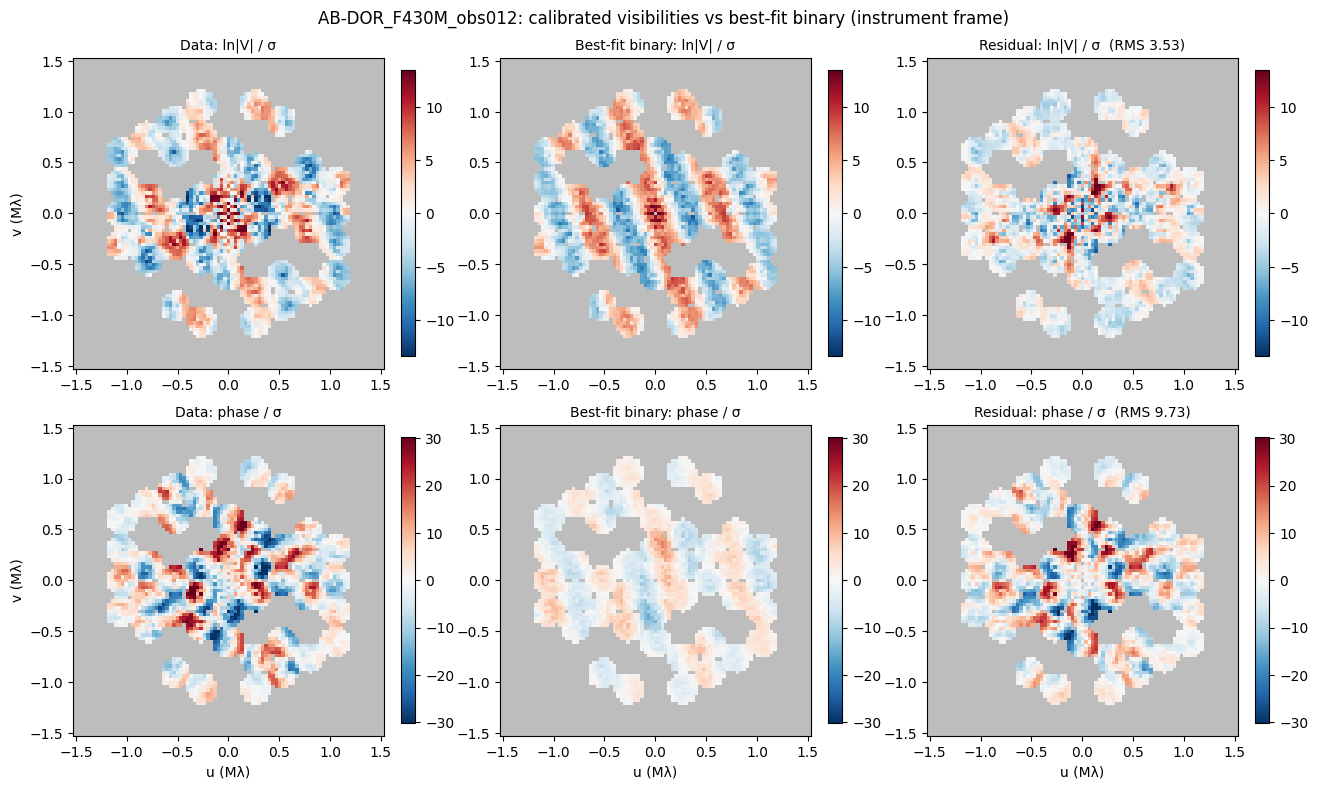

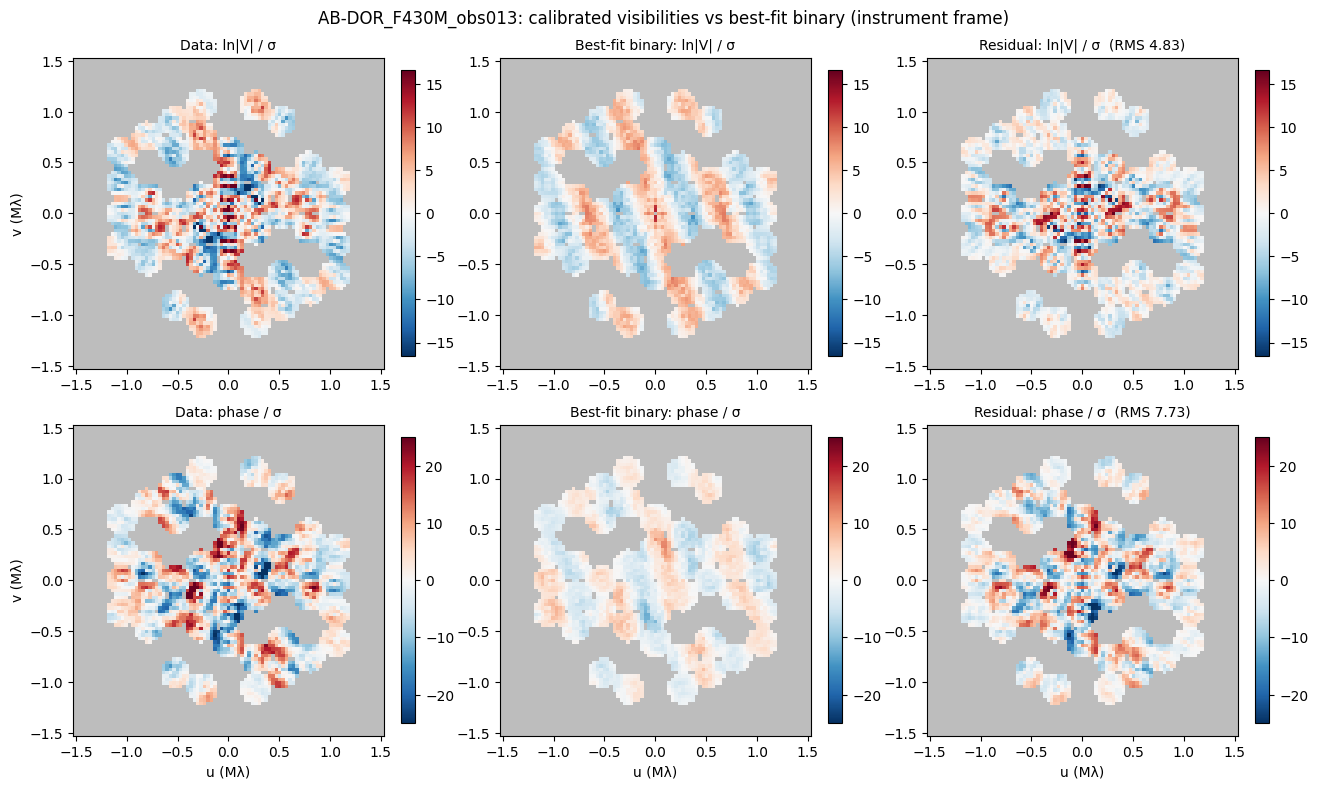

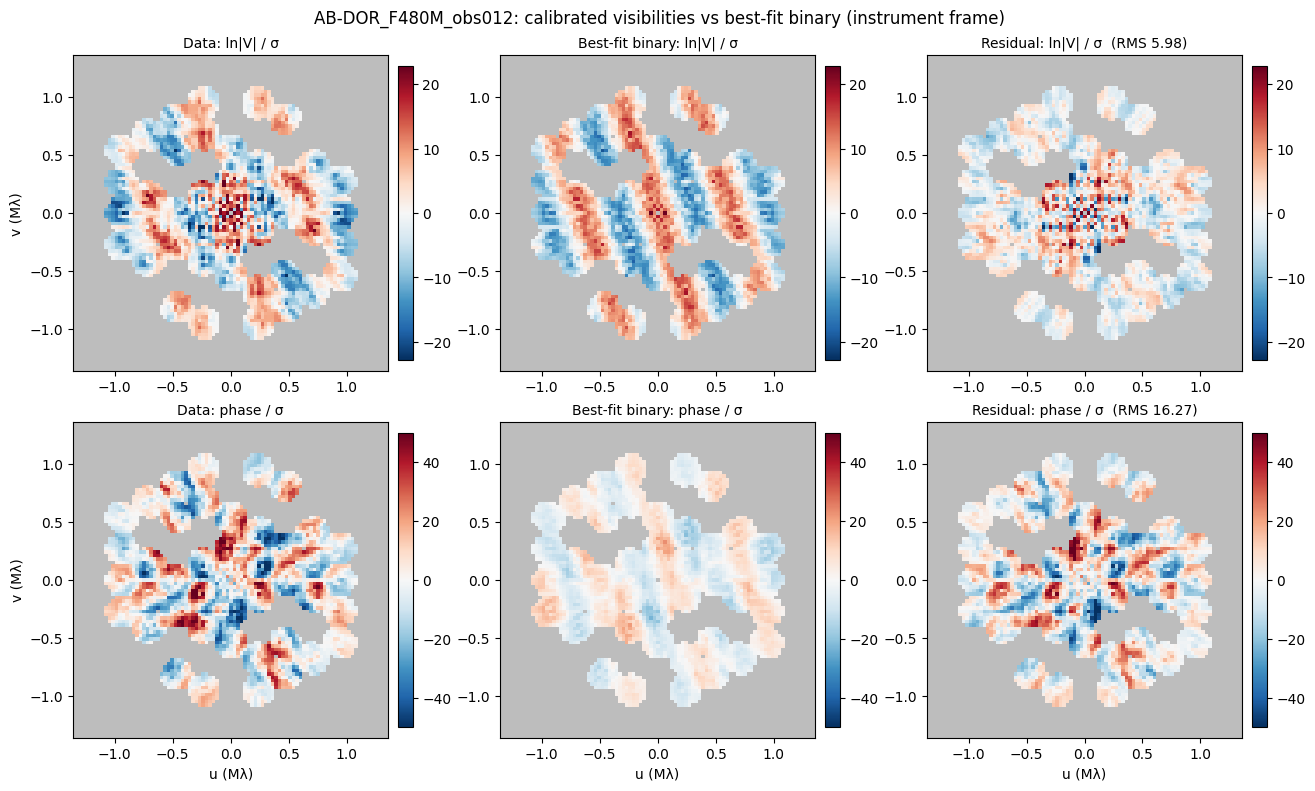

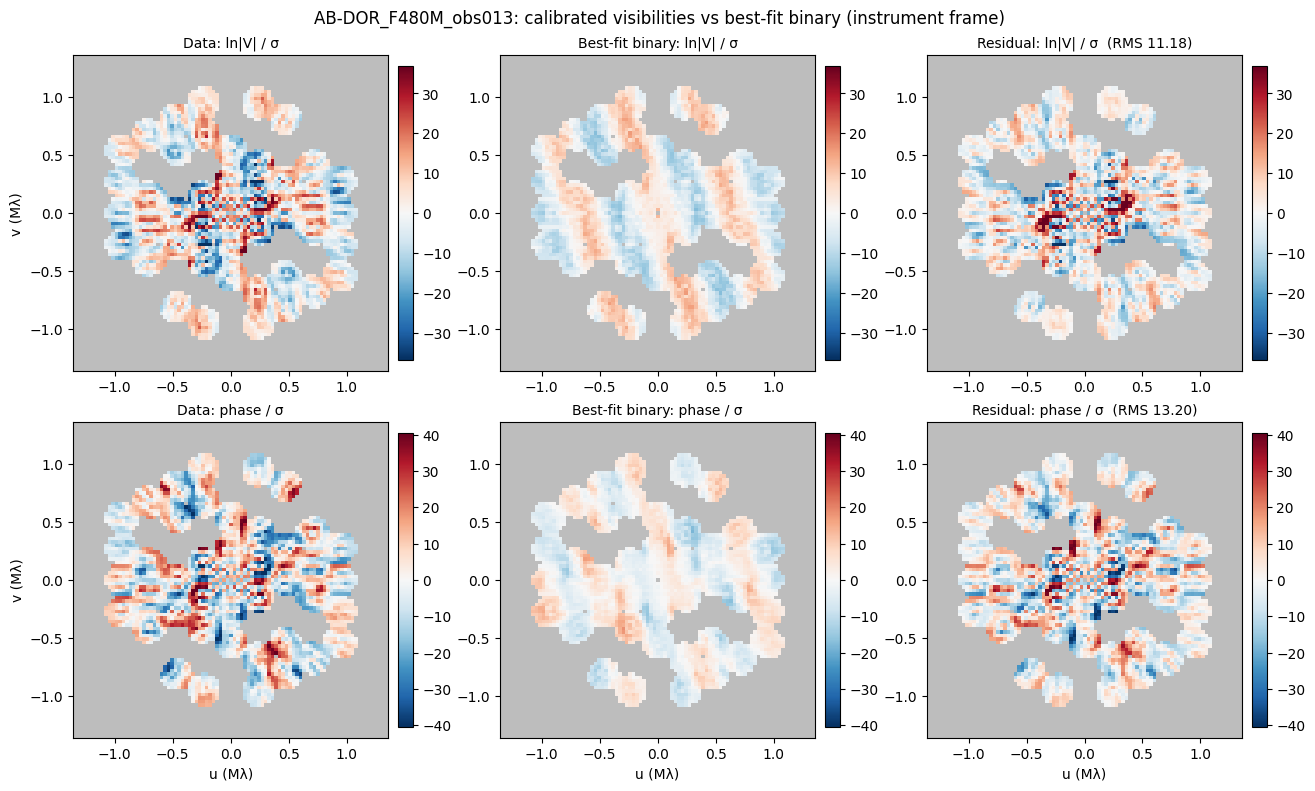

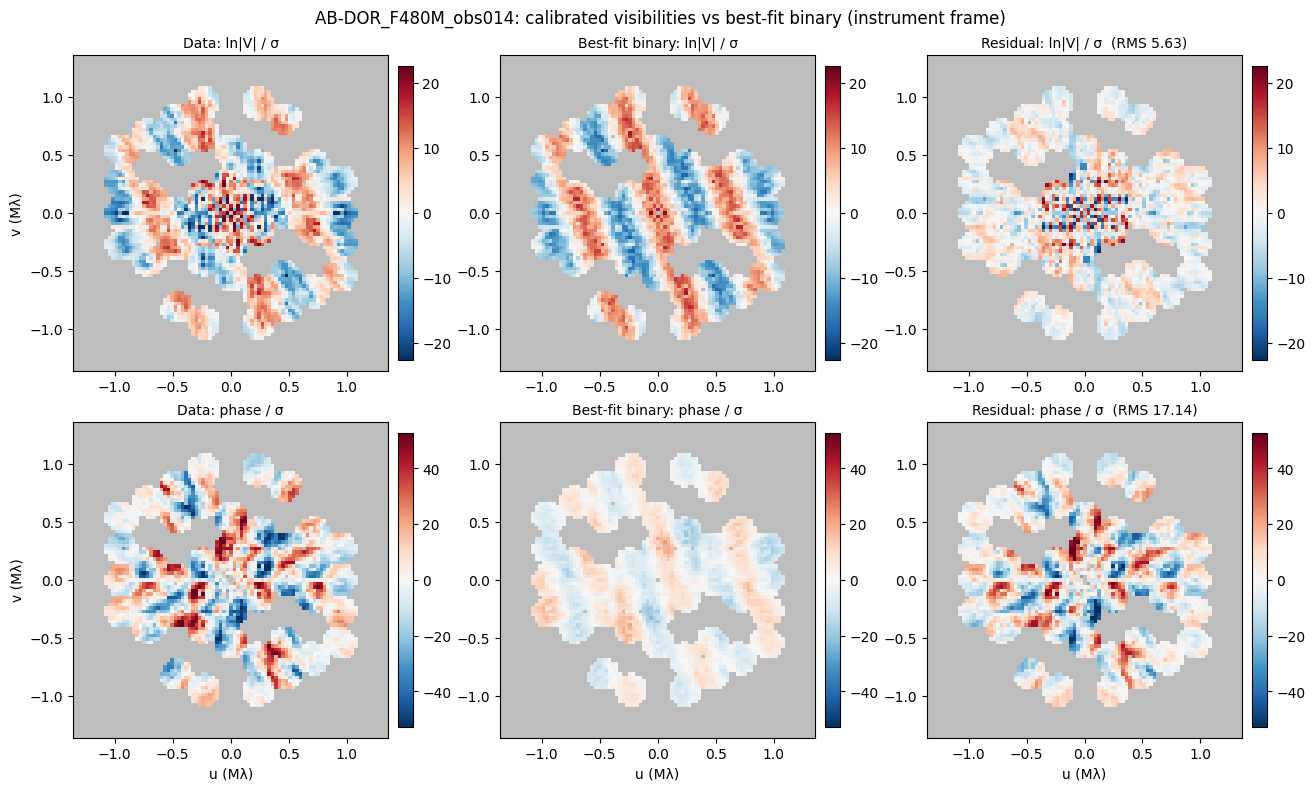

In [17]:
for name, disco in discos.items():
    c = results[name].summary["companion"]
    binary = System(
        star=PointSource(),
        C=PointSource(flux=c["flux"], dra=c["dra_mas"], ddec=c["ddec_mas"]),
    )
    pipeline_plots.uv_model_comparison(
        output_path, name, disco, binary, label="best-fit binary"
    )
    plt.show()